# 모델 1. 단순 선형회귀 (녹지 비율만)
**작성자: A**

질문: **녹지 하나로 얼마나 설명되나?**

6주차 3단계 '베이스라인 먼저': 서울 평균(아무것도 안 함) 기준선도 여기서 같이 돌림

In [14]:
# ── 공통 설정 (모든 노트북 맨 위에 그대로 두기) ──
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/AICEE_project'   # 모두 같은 경로 (공유 폴더를 '내 드라이브에 바로가기 추가' 해야 함)
DATA = f'{BASE}/data_processed'
RESULTS = f'{BASE}/results'

import sys
sys.path.append(f'{BASE}/shared')
RANDOM_STATE = 42

USE_DUMMY = False   # ← 진짜 데이터 나오면 False로 바꾸기

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


> **강의 규칙 (5·6주차)** — 튜닝은 교차검증 점수로만 · 전처리는 Pipeline 안에 · 바꾼 설정은 `note`에 기록 · 테스트 데이터는 C만

### 입력 변수 · 녹지 300m 하나만 사용

In [15]:
FEATURES = ['green_300', 'impervious_300', 'water_300', 'dist_han_m']   # 확정되면 팀 공통으로 수정
TARGETS = ['uhi_day', 'uhi_night']   # 낮·밤 열섬 강도

### train.csv 불러오기 (810개 센서, 20개 구)

In [16]:
import pandas as pd
df = pd.read_csv(f'{DATA}/train_dummy.csv' if USE_DUMMY else f'{DATA}/train.csv')
print(df.shape); df.head()

(810, 10)


,sensor_id,gu,lat,lon,uhi_day,uhi_night,green_300,impervious_300,water_300,dist_han_m
0,V02Q1940655,종로구,37.580051,126.985146,0.237771,-0.454854,0.095686,0.901422,0.0,5353.0
1,V02Q1940539,종로구,37.576920,127.004514,0.865449,0.921336,0.053266,0.946734,0.0,4127.0
2,V02Q1940737,종로구,37.605426,126.967435,-0.297051,-1.650092,0.423855,0.575904,0.0,7615.0
3,V02Q1940721,종로구,37.586059,127.000838,-0.003301,0.213598,0.071825,0.928175,0.0,5184.0
4,V02Q1940522,종로구,37.577075,127.012367,-0.135442,-0.231452,0.068691,0.930827,0.0,3839.0


### 모델1 학습 · 구 단위 교차검증 (낮·밤 따로)

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from evaluate import cv_by_district, save_cv_result, worst_sensors

X_COLS = ['green_300']
NOTE = '녹지 300m 하나 (최종)'   # ← 설정 바꿀 때마다 적기 (6주차: 시도한 모든 설정 기록)
results = {}
for target in TARGETS:
    model = make_pipeline(StandardScaler(), LinearRegression())
    overall, per_gu, oof = cv_by_district(model, df[X_COLS], df[target], groups=df['gu'])
    save_cv_result('model1_LR', target, overall, BASE, note=NOTE)
    results[target] = (overall, per_gu, oof)
    print(target, {k: round(v, 3) for k, v in overall.items()})

[진짜 데이터 점수 기록] /content/drive/MyDrive/AICEE_project/results/cv_scores.csv
uhi_day {'RMSE': 0.635, 'MAE': 0.471, 'R2': 0.098, 'RMSE_fold_mean': 0.61, 'RMSE_fold_sd': 0.148}
[진짜 데이터 점수 기록] /content/drive/MyDrive/AICEE_project/results/cv_scores.csv
uhi_night {'RMSE': 0.623, 'MAE': 0.452, 'R2': 0.262, 'RMSE_fold_mean': 0.6, 'RMSE_fold_sd': 0.198}


## 기준선: 서울 평균

In [18]:
for t in TARGETS:
    o, _, _ = cv_by_district(DummyRegressor(strategy='mean'), df[X_COLS], df[t], groups=df['gu'])
    save_cv_result('baseline_mean', t, o, BASE)
    print(t, {k: round(v, 3) for k, v in o.items()})

[진짜 데이터 점수 기록] /content/drive/MyDrive/AICEE_project/results/cv_scores.csv
uhi_day {'RMSE': 0.671, 'MAE': 0.484, 'R2': -0.008, 'RMSE_fold_mean': 0.643, 'RMSE_fold_sd': 0.165}
[진짜 데이터 점수 기록] /content/drive/MyDrive/AICEE_project/results/cv_scores.csv
uhi_night {'RMSE': 0.733, 'MAE': 0.538, 'R2': -0.023, 'RMSE_fold_mean': 0.719, 'RMSE_fold_sd': 0.197}


## 잔차 분석 (3주차: 잔차 그림이 정직한 검사)

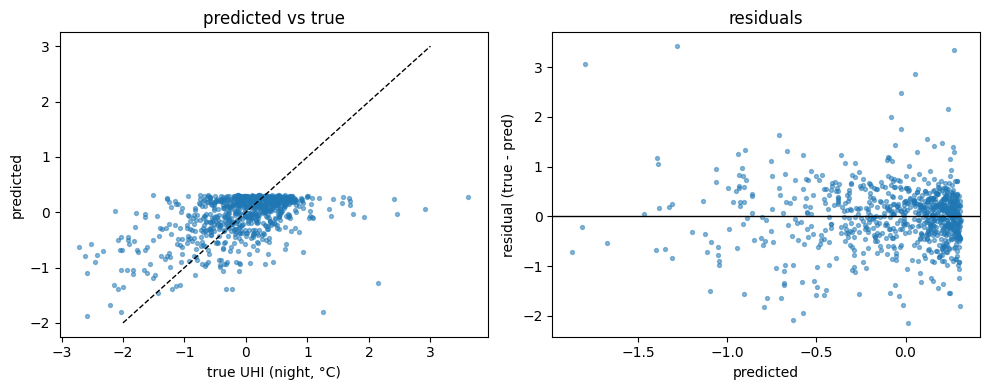

,held_out_gu,n_sensors,RMSE,MAE,R2
1,강북구,26,0.994189,0.707388,-0.220546
7,도봉구,33,0.898147,0.681815,0.094863
11,서초구,32,0.836608,0.518168,0.004555
17,종로구,51,0.773368,0.631010,0.193495
16,은평구,26,0.757870,0.639772,-0.525562


In [19]:
import matplotlib.pyplot as plt
overall, per_gu, oof = results['uhi_night']
resid = df['uhi_night'] - oof
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(df['uhi_night'], oof, s=8, alpha=0.5); ax[0].plot([-2, 3], [-2, 3], 'k--', lw=1)
ax[0].set_xlabel('true UHI (night, °C)'); ax[0].set_ylabel('predicted'); ax[0].set_title('predicted vs true')
ax[1].scatter(oof, resid, s=8, alpha=0.5); ax[1].axhline(0, color='k', lw=1)
ax[1].set_xlabel('predicted'); ax[1].set_ylabel('residual (true - pred)'); ax[1].set_title('residuals')
plt.tight_layout()
plt.savefig(f'{RESULTS}/A_fig2_residuals.png', dpi=200)
plt.show()
per_gu.sort_values('RMSE', ascending=False).head()   # 어느 구에서 특히 틀리나 (부분집단 분석)

## 실패 사례 후보 (6주차 7단계: 최소 3개)
오차가 큰 센서를 로드뷰·지도로 확인해서 **왜 틀렸는지** 메모

### 밤 오차가 큰 센서 10개
구 단위 교차검증 예측으로 잔차(실제 − 예측)를 구하고, 절댓값이 큰 10개를 저장(results/A_worst_sensors_night.csv). 여기서 만든 chk는 아래 잔차 분석 셀들에서 계속 사용

In [22]:
# 밤 기준 오차가 큰 센서 10개 (실제가 예측보다 더 덥거나 더 시원한 곳)
overall, per_gu, oof = results['uhi_night']
chk = df[['sensor_id', 'gu', 'lat', 'lon', 'green_300', 'uhi_night']].copy()
chk['pred'] = oof
chk['resid'] = chk['uhi_night'] - chk['pred']
chk['abs_resid'] = chk['resid'].abs()
top = chk.sort_values('abs_resid', ascending=False).head(10)
top.to_csv(f'{RESULTS}/A_worst_sensors_night.csv', index=False)
top.round(2)

,sensor_id,gu,lat,lon,green_300,uhi_night,pred,resid,abs_resid
769,OC3CL200238,서초구,37.47,127.03,0.67,2.14,-1.28,3.42,3.42
403,V02Q1940773,양천구,37.53,126.86,0.00,3.61,0.27,3.34,3.34
775,OC3CL200249,강북구,37.62,127.04,0.90,1.26,-1.80,3.05,3.05
777,OC3CL200256,성동구,37.57,127.04,0.09,2.91,0.05,2.86,2.86
115,V02Q1940733,성동구,37.55,127.06,0.12,2.46,-0.02,2.49,2.49
104,V02Q1940758,성동구,37.56,127.03,0.01,2.40,0.24,2.16,2.16
215,V02Q1940329,도봉구,37.68,127.04,0.13,-2.13,0.01,-2.14,2.14
243,V02Q1940128,노원구,37.67,127.08,0.42,-2.71,-0.63,-2.08,2.08
32,V02Q1940844,종로구,37.58,127.01,0.16,1.91,-0.08,2.00,2.00
234,V02Q1940325,도봉구,37.69,127.04,0.40,-2.51,-0.58,-1.94,1.94


### 밤 오차 상위 센서 거리뷰 링크
밤 오차 상위 10개 센서의 좌표로 네이버 지도 링크를 만들어 센서 주변 환경(건물 밀집, 공원, 산 아래)을 직접 확인

In [23]:
for _, r in top.head(10).iterrows():
    print(r['sensor_id'], r['gu'], f"https://map.naver.com/p?c={r['lon']},{r['lat']},19,0,0,0,dh")

OC3CL200238 서초구 https://map.naver.com/p?c=127.0335605,37.4719635,19,0,0,0,dh
V02Q1940773 양천구 https://map.naver.com/p?c=126.859175524,37.528560458,19,0,0,0,dh
OC3CL200249 강북구 https://map.naver.com/p?c=127.042386,37.622123,19,0,0,0,dh
OC3CL200256 성동구 https://map.naver.com/p?c=127.036088628704,37.5716201595004,19,0,0,0,dh
V02Q1940733 성동구 https://map.naver.com/p?c=127.056597845,37.54818971,19,0,0,0,dh
V02Q1940758 성동구 https://map.naver.com/p?c=127.031606382,37.560119488,19,0,0,0,dh
V02Q1940329 도봉구 https://map.naver.com/p?c=127.044592639,37.680506067,19,0,0,0,dh
V02Q1940128 노원구 https://map.naver.com/p?c=127.081840073,37.674109621,19,0,0,0,dh
V02Q1940844 종로구 https://map.naver.com/p?c=127.01458637,37.579110321,19,0,0,0,dh
V02Q1940325 도봉구 https://map.naver.com/p?c=127.041879527,37.68923847,19,0,0,0,dh


### 센서 종류별 평균 잔차
공원 CCTV형(OC3CL) 센서가 체계적으로 덥게 나오는지 확인. 평균 잔차 −0.14℃로 그렇지 않음 → 공원 사례는 개별 센서 문제

In [24]:
grp = chk.copy()
grp['종류'] = grp['sensor_id'].str[:5]
grp.groupby('종류')[['green_300', 'uhi_night', 'resid']].agg(['mean', 'count']).round(2)

green_300       uhi_night       resid      
           mean count      mean count  mean count
종류                                               
OC3CL      0.22   105     -0.36   105 -0.14   105
OC3DL      0.15     4     -0.32     4 -0.27     4
OC3KL      0.02     2     -0.95     2 -1.21     2
V02Q1      0.14   693     -0.00   693  0.04   693
V02Q2      0.20     6     -1.33     6 -1.20     6

### 밤 잔차 지도
센서 위치에 잔차를 색으로 표시(빨강=예측보다 더움, 파랑=예측보다 시원함). 파란 점은 산 가장자리, 빨간 점은 평지 밀집 지역에 몰림

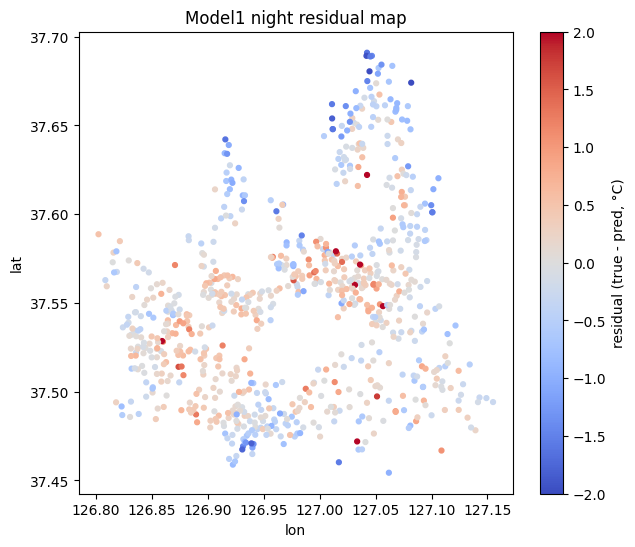

In [25]:
fig, ax = plt.subplots(figsize=(7, 6))
sc = ax.scatter(chk['lon'], chk['lat'], c=chk['resid'], cmap='coolwarm', vmin=-2, vmax=2, s=12)
plt.colorbar(sc, label='residual (true - pred, °C)')
ax.set_title('Model1 night residual map'); ax.set_xlabel('lon'); ax.set_ylabel('lat')
plt.savefig(f'{RESULTS}/A_fig3_residual_map.png', dpi=200)
plt.show()

### 낮 오차가 큰 센서 10개
낮 잔차 상위 10개를 저장(results/A_worst_sensors_day.csv)하고 거리뷰 링크 출력. 종로구 5개 등 대부분 예측보다 2~3℃ 더운 V02Q 센서 → 01번에서 42℃ 초과 센서와 비교

In [26]:
# 낮 기준 오차가 큰 센서 10개
overall_d, per_gu_d, oof_d = results['uhi_day']
chk_d = df[['sensor_id', 'gu', 'lat', 'lon', 'green_300', 'uhi_day']].copy()
chk_d['pred'] = oof_d
chk_d['resid'] = chk_d['uhi_day'] - chk_d['pred']
chk_d['abs_resid'] = chk_d['resid'].abs()
top_d = chk_d.sort_values('abs_resid', ascending=False).head(10)
top_d.to_csv(f'{RESULTS}/A_worst_sensors_day.csv', index=False)
for _, r in top_d.iterrows():
    print(r['sensor_id'], r['gu'], round(r['uhi_day'], 2), round(r['resid'], 2),
          f"https://map.naver.com/p?c={r['lon']},{r['lat']},19,0,0,0,dh")

V02Q1940817 종로구 2.98 3.11 https://map.naver.com/p?c=126.996923175,37.584479904,19,0,0,0,dh
V02Q1940844 종로구 2.96 2.97 https://map.naver.com/p?c=127.01458637,37.579110321,19,0,0,0,dh
V02Q1940676 관악구 -3.11 -2.47 https://map.naver.com/p?c=126.922519447,37.458885296,19,0,0,0,dh
V02Q1940397 동작구 -2.72 -2.39 https://map.naver.com/p?c=126.964650522,37.487703409,19,0,0,0,dh
V02Q1940796 종로구 2.46 2.39 https://map.naver.com/p?c=127.019982768,37.574848152,19,0,0,0,dh
V02Q1940643 마포구 2.11 2.1 https://map.naver.com/p?c=126.912963429,37.544351645,19,0,0,0,dh
V02Q1940773 양천구 2.25 2.03 https://map.naver.com/p?c=126.859175524,37.528560458,19,0,0,0,dh
V02Q1940710 종로구 2.0 2.0 https://map.naver.com/p?c=127.01562884,37.577843118,19,0,0,0,dh
V02Q1940944 중랑구 2.07 1.96 https://map.naver.com/p?c=127.075432599,37.60504164,19,0,0,0,dh
V02Q1940843 종로구 2.05 1.95 https://map.naver.com/p?c=126.98591264,37.578936514,19,0,0,0,dh


## 잔차 분석: 모델1이 크게 틀린 센서
구 단위 교차검증 예측으로 밤 잔차(실제 − 예측)를 구하고, 절댓값이 큰 센서 10개를 네이버 거리뷰(2022~2026년 사진)로 확인했다. 결과는 results/A_worst_sensors_night.csv에 저장했다.

**(A) 건물·공장 밀집 → 예측보다 더움 (5곳)**
양천구 신정동(V02Q1940773, 밤 +3.6℃, 서울 최고), 성동구 성수동·행당동·마장동, 종로구 창신동. 녹지는 0~16%로 낮지만 빌라·공장이 붙은 좁은 골목이라 열이 빠지지 않는다. 저층 빌라가 사방을 둘러싼 좁은 골목의 CCTV 기둥에 설치. 주변 건물 벽에 에어컨 실외기가 있음.

**(B) 공원 속 기둥 → 예측보다 더움 (2곳)**
서초구 양재동(OC3CL200238), 강북구 북서울꿈의숲(OC3CL200249). 녹지 67~90%인데 밤이 따뜻하다. 센서가 CCTV 기둥에 달려 있고 옆에 장비 함, 포장 길, 돌담이 있다.

**(C) 산 아래 → 예측보다 시원함 (3곳)**
도봉구 도봉동 2곳, 노원구 상계동(V02Q1940128, 밤 −2.7℃, 서울 최저). 산비탈과 하천 바로 옆이라 밤에 산에서 찬 공기가 내려온다.

**결론:** 300m 녹지 비율 하나로는 건물 밀집, 센서 바로 옆 환경, 지형(산·하천) 효과를 설명하지 못한다. 모델2~4에서 불투수면·물·한강 거리를 더하면 (A)와 (C)가 얼마나 줄어드는지가 비교 포인트다.

참고: OC3CL(공원 CCTV) 센서 전체의 평균 잔차는 −0.14℃로, 이 종류가 체계적으로 덥게 나오지는 않았다. 위 사례는 그룹 전체의 특징이 아니라 개별 센서의 사례다.

**(D) 낮 직사광선·인공 열원 → 낮에 예측보다 더움**
낮 오차 상위 10개(results/A_worst_sensors_day.csv) 중 5개가 42℃를 넘은 기록이 있는 센서다.
- 직사광선: 종로구 명륜3가(V02Q1940817, 낮 오차 1위 +3.1℃)는 센서가 하얀 건물 벽에 바짝 붙어 있고, 그늘 없이 햇빛을 정면으로 받는다. 벽에 반사된 햇빛까지 받아 센서가 달궈졌을 수 있다.
- 인공 열원: 중랑구 묵동(V02Q1940944, 낮 +2.1℃)은 기둥 주변에 실외기·배기 덕트·변압기 등 열을 내는 설비가 몰려 있다. (사진 기반 추정)
두 곳 모두 동네가 더운 것이 아니라 센서 자리가 뜨거웠을 가능성이 크다

## 보고서용 메모

* 결과 (RMSE 평균 ± 표준편차): 구 단위 교차검증(train 810개, 20개 구)에서 녹지 300m 하나로 낮 0.61 ± 0.15℃, 밤 0.60 ± 0.20℃. 기준선(서울 평균)은 낮 0.64 ± 0.17℃, 밤 0.72 ± 0.20℃라 모델1이 낮·밤 모두 더 낫다. R²는 낮 0.10, 밤 0.26으로 녹지의 냉각 효과가 밤에 더 뚜렷하다.

* 한계: 입력이 녹지 비율 하나라 예측값이 −2~+0.3℃ 좁은 범위에 몰리고, 아주 덥거나 시원한 센서를 못 맞힌다. 300m 평균이라 센서 바로 옆 환경(실외기, 장비 함, 포장면)과 지형(산·하천)을 반영하지 못한다. 구마다 점수 차이가 커서(일부 구 R² 음수) 지역에 따라 성능이 불안정하다.

* 실패 사례: 오차 상위 10개 센서를 거리뷰로 확인한 결과 세 유형으로 나뉜다. (A) 건물·공장 밀집 골목은 예측보다 더움(양천구 신정동 +3.6℃, 빌라 밀집 골목), (B) 공원 속 CCTV 기둥은 녹지가 많아도 더움(강북구 북서울꿈의숲), (C) 산 아래·하천 옆은 예측보다 시원함(노원구 상계동 −2.7℃). 공원 CCTV형 센서 전체 평균 잔차는 −0.14℃라 체계적 문제는 아님.

* 생성형 AI 사용 내역: 도구 Claude. 프롬프트 예: "오차 큰 센서 뽑는 코드", "로드뷰 링크 만드는 코드", "센서 종류별 평균 잔차 비교". 잔차 상위 10개 추출, 지도 링크, 종류별 비교 코드를 받아 사용함. 거리뷰 사진은 직접 찾아 확인했고, 센서 위치와 주변 환경 판단은 사진으로 직접 검토함. 수정한 부분: 처음 제안된 파일 경로가 코랩에서 열리지 않아 노트북의 변수를 그대로 쓰도록 바꿈. AI가 제시한 'OC3CL 센서가 체계적으로 덥다'는 가설을 종류별 비교로 확인해 기각함.